# Positional Embeddings

Self-attention treats its input as a **set** — it has no built-in notion of order.  
Give it the tokens of *"cat sat on mat"* in any order and it produces the same result.  
**Positional Embeddings** are the fix: they inject sequence position information into every token's representation.

## Overview
This notebook covers positional representation methods and a complete Transformer Encoder:
1. **Motivation**: Why self-attention is permutation-equivariant and position-blind.
2. **Requirements**: Properties of effective positional encoding schemes.
3. **Sinusoidal Encoding**: Mathematical derivation of fixed sine and cosine waves.
4. **Visualizing Encodings**: Heatmaps, frequency bands, and vector additions.
5. **Key Properties**: Relative positions and distance encoding through dot products.
6. **Learned Positional Embeddings**: BERT-style lookup tables.
7. **Rotary Position Embedding (RoPE)**: Relative position encoding in modern LLMs.
8. **Attention with Linear Biases (ALiBi)**: Length extrapolation techniques.
9. **Transformer Encoder**: End-to-end PyTorch implementation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

---
## 1. Motivation: Position-Blind Attention

Self-attention computes for each token a weighted sum over **all other tokens**.  
The computation only uses the token vectors themselves — **not their positions**.

### A concrete problem

Consider the two sentences:
- *"The dog bit the man."*
- *"The man bit the dog."*

Both contain exactly the same words. A self-attention layer that ignores order would produce **identical representations** for both — yet they have opposite meanings.

### Why not just use indices?

You might think: just append the token index (0, 1, 2, …) to the embedding.  
Problems:
1. **Unbounded**: index 500 is much larger than index 1 — scaling distorts the embedding space.
2. **Unseen lengths**: if we train on sequences up to length 50 but see length 200 at inference, the model has never seen those position values.
3. **No model of relative distance**: the distance between positions 1 and 2 looks the same as between 10 and 11, but also the same as between 1 and 10.

We need something **bounded, smooth, and expressive about relative gaps**.

In [2]:
# ─────────────────────────────────────────────────────────────────────────────
# Demonstrate that self-attention without PE is permutation-invariant
# ─────────────────────────────────────────────────────────────────────────────

def softmax(x):
    e = np.exp(x - x.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)

def self_attention(X):
    """Simple scaled dot-product self-attention (identity W_Q=W_K=W_V for demo)."""
    d = X.shape[-1]
    scores  = X @ X.T / np.sqrt(d)
    weights = softmax(scores)
    return weights @ X, weights

# Two sentences: same words, different order
#   s1: [cat, sat, mat]
#   s2: [mat, cat, sat]   — a permutation of s1

cat = np.array([1.0, 0.2, 0.1])
sat = np.array([0.1, 1.0, 0.3])
mat = np.array([0.2, 0.1, 1.0])

X1 = np.array([cat, sat, mat])   # original order
X2 = np.array([mat, cat, sat])   # permuted

out1, w1 = self_attention(X1)
out2, w2 = self_attention(X2)

print("=" * 55)
print("Self-attention WITHOUT positional embeddings")
print("=" * 55)
tokens1 = ["cat", "sat", "mat"]
tokens2 = ["mat", "cat", "sat"]

print("\nOrder 1: cat → sat → mat")
for tok, vec in zip(tokens1, out1):
    print(f"  {tok:4s}  output: {np.round(vec, 3)}")

print("\nOrder 2: mat → cat → sat")
for tok, vec in zip(tokens2, out2):
    print(f"  {tok:4s}  output: {np.round(vec, 3)}")

# Find matching tokens and compare
print("\nAre outputs for 'cat' identical in both orderings?")
cat_out1 = out1[0]          # cat in position 0 of order1
cat_out2 = out2[1]          # cat in position 1 of order2
print(f"  Order 1: {np.round(cat_out1, 4)}")
print(f"  Order 2: {np.round(cat_out2, 4)}")
print(f"  Identical? {np.allclose(cat_out1, cat_out2)}")
print()
print("→ YES — same output regardless of position.")
print("  The model cannot distinguish 'cat sat mat' from 'mat cat sat'.")

Self-attention WITHOUT positional embeddings

Order 1: cat → sat → mat
  cat   output: [0.517 0.4   0.412]
  sat   output: [0.378 0.516 0.449]
  mat   output: [0.394 0.394 0.542]

Order 2: mat → cat → sat
  mat   output: [0.394 0.394 0.542]
  cat   output: [0.517 0.4   0.412]
  sat   output: [0.378 0.516 0.449]

Are outputs for 'cat' identical in both orderings?
  Order 1: [0.5169 0.3996 0.4119]
  Order 2: [0.5169 0.3996 0.4119]
  Identical? True

→ YES — same output regardless of position.
  The model cannot distinguish 'cat sat mat' from 'mat cat sat'.


---
## 2. Requirements for Positional Encodings

Any positional encoding scheme should fulfil several properties:

| Property | Meaning |
|----------|---------|
| **Unique per position** | Each position gets a distinct encoding — the model can tell positions apart |
| **Bounded values** | Values stay in a fixed range (e.g. [-1, 1]) regardless of sequence length |
| **Smooth / continuous** | Close positions should have similar encodings — nearby tokens feel "nearby" |
| **Relative distance** | The encoding of position $p+k$ should be expressible as a function of the encoding of $p$ — the model can generalise to relative gaps |
| **Generalisable to long sequences** | Works on sequences longer than seen during training |

The sinusoidal encoding from *Attention Is All You Need* (Vaswani et al., 2017) satisfies **all of the above**.

---
## 3. Sinusoidal Positional Encoding

### The Formula

For a token at position $pos$ and embedding dimension index $i$:

$$PE_{(pos,\, 2i)} = \sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

$$PE_{(pos,\, 2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

Even-indexed dimensions use **sine**, odd-indexed use **cosine**.  
Each pair of dimensions $(2i, 2i+1)$ oscillates at a different **frequency**.

### Breaking it down

$$\omega_i = \frac{1}{10000^{2i/d_{model}}}$$

- $\omega_i$ is the **angular frequency** for dimension pair $i$
- As $i$ grows, $\omega_i$ shrinks → **lower frequency** → slower oscillation along positions
- Dimension pair 0 oscillates **fastest** (period ≈ 2π positions)
- The last dimension pair oscillates super-slowly (period ≈ 10000 × 2π positions)

> **Analogy: binary clock**  
> Think of a binary number like `0110 1001`. The rightmost bit flips every step, the next flips every 2 steps, then every 4 steps, etc.  
> Sinusoidal PE works the same way — high-frequency (low-$i$) dimensions encode fine-grained position; low-frequency (high-$i$) dimensions encode coarse position.

### Why 10000?
It's a hyperparameter chosen so that:
- Frequencies span the full useful range of wavelengths from "token-level" to "sequence-level"
- For typical sequence lengths (≤ 10,000 tokens), every position gets a unique signature

In [3]:
def sinusoidal_pe(max_len, d_model):
    """
    Compute sinusoidal positional encodings.

    Parameters
    ----------
    max_len : int   — maximum sequence length
    d_model : int   — embedding dimension (must be even)

    Returns
    -------
    PE : ndarray of shape (max_len, d_model)
    """
    # positions: column vector  (max_len, 1)
    pos = np.arange(max_len)[:, np.newaxis]           # (max_len, 1)

    # dimension indices for even positions only: 0, 2, 4, ... → i = 0, 1, 2, ...
    i   = np.arange(0, d_model, 2)[np.newaxis, :]     # (1, d_model/2)

    # angular frequencies  ω_i = 1 / 10000^(2i/d_model)
    omega = 1.0 / np.power(10000.0, i / d_model)      # (1, d_model/2)

    # arguments for sin/cos
    angles = pos * omega                               # (max_len, d_model/2)

    PE = np.zeros((max_len, d_model))
    PE[:, 0::2] = np.sin(angles)   # even dims  → sine
    PE[:, 1::2] = np.cos(angles)   # odd  dims  → cosine

    return PE


# ── Quick sanity check ───────────────────────────────────────────────────────
PE = sinusoidal_pe(max_len=50, d_model=16)

print(f"PE shape  : {PE.shape}   (50 positions × 16 dimensions)")
print(f"PE values range from {PE.min():.3f} to {PE.max():.3f}  (bounded in [-1, 1])")
print()
print("First 4 positions, first 8 dimensions:")
header = "  pos  " + "  ".join([f"dim{j}" for j in range(8)])
print(header)
for p in range(4):
    row = f"  {p:3d}  " + "  ".join([f"{PE[p,d]:+.3f}" for d in range(8)])
    print(row)
print()
print("Note: dim0 (sin) and dim1 (cos) form a pair at the same frequency.")

PE shape  : (50, 16)   (50 positions × 16 dimensions)
PE values range from -1.000 to 1.000  (bounded in [-1, 1])

First 4 positions, first 8 dimensions:
  pos  dim0  dim1  dim2  dim3  dim4  dim5  dim6  dim7
    0  +0.000  +1.000  +0.000  +1.000  +0.000  +1.000  +0.000  +1.000
    1  +0.841  +0.540  +0.311  +0.950  +0.100  +0.995  +0.032  +1.000
    2  +0.909  -0.416  +0.591  +0.807  +0.199  +0.980  +0.063  +0.998
    3  +0.141  -0.990  +0.813  +0.583  +0.296  +0.955  +0.095  +0.996

Note: dim0 (sin) and dim1 (cos) form a pair at the same frequency.


---
## 4. Visualizing Positional Encodings

### 4.1  The PE Matrix Heatmap — "Fingerprints"

Each row is the positional encoding vector for one token position.  
Each column is one embedding dimension.  
Patterns you'll see:
- **Left columns (low i)**: fast oscillations — stripes running along positions
- **Right columns (high i)**: slow oscillations — gradual gradients
- Every row is **unique** — no two positions have the same pattern

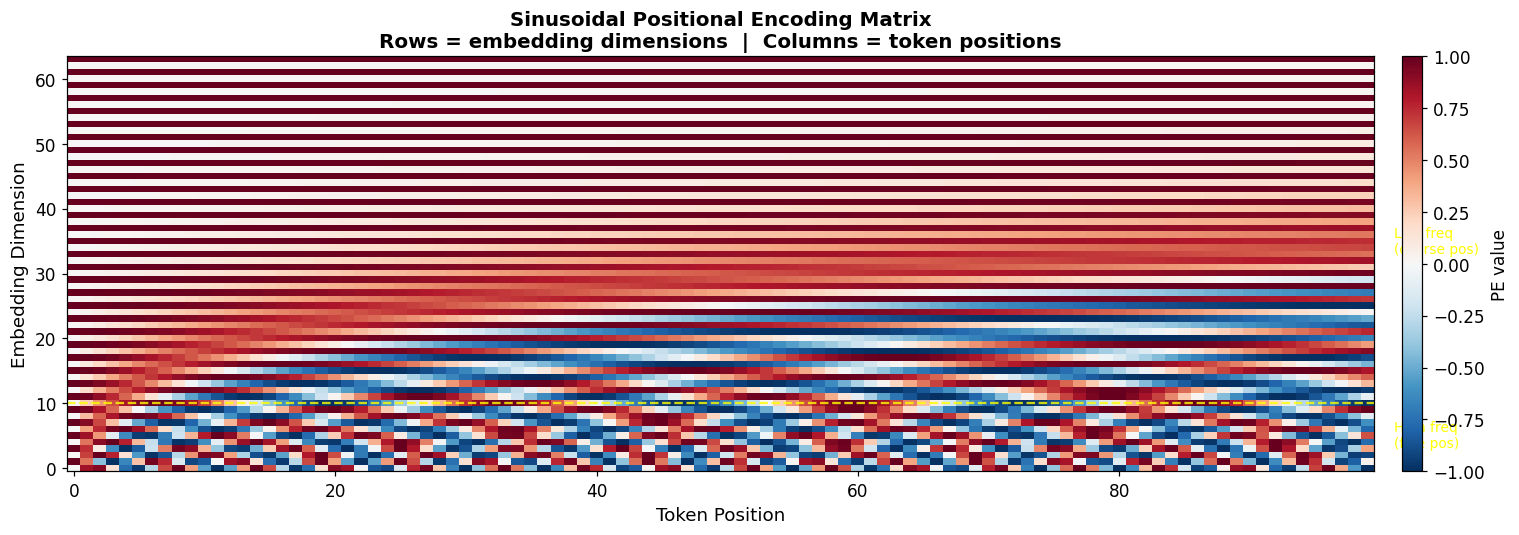

Each column = one token's positional 'fingerprint'.
No two columns are identical → every position is uniquely identifiable.


In [4]:
# ── 4.1  Heatmap of the full PE matrix ──────────────────────────────────────
PE_vis = sinusoidal_pe(max_len=100, d_model=64)

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(PE_vis.T, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1,
               origin='lower')
plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label='PE value')
ax.set_xlabel('Token Position', fontsize=12)
ax.set_ylabel('Embedding Dimension', fontsize=12)
ax.set_title('Sinusoidal Positional Encoding Matrix\n'
             'Rows = embedding dimensions  |  Columns = token positions',
             fontsize=13, fontweight='bold')
# Annotate frequency regions
ax.axhline(10, color='yellow', lw=1.5, ls='--', alpha=0.8)
ax.text(101, 5,  'High freq\n(fine pos)',  color='yellow', fontsize=9, va='center')
ax.text(101, 35, 'Low freq\n(coarse pos)', color='yellow', fontsize=9, va='center')
plt.tight_layout()
plt.show()

print("Each column = one token's positional 'fingerprint'.")
print("No two columns are identical → every position is uniquely identifiable.")

### 4.2  Individual Frequency Waves

Each dimension pair $(2i, 2i+1)$ is a sin/cos pair at the same frequency.  
The first pair oscillates ~6× per 100 positions; the last pair barely completes a fraction of a cycle.

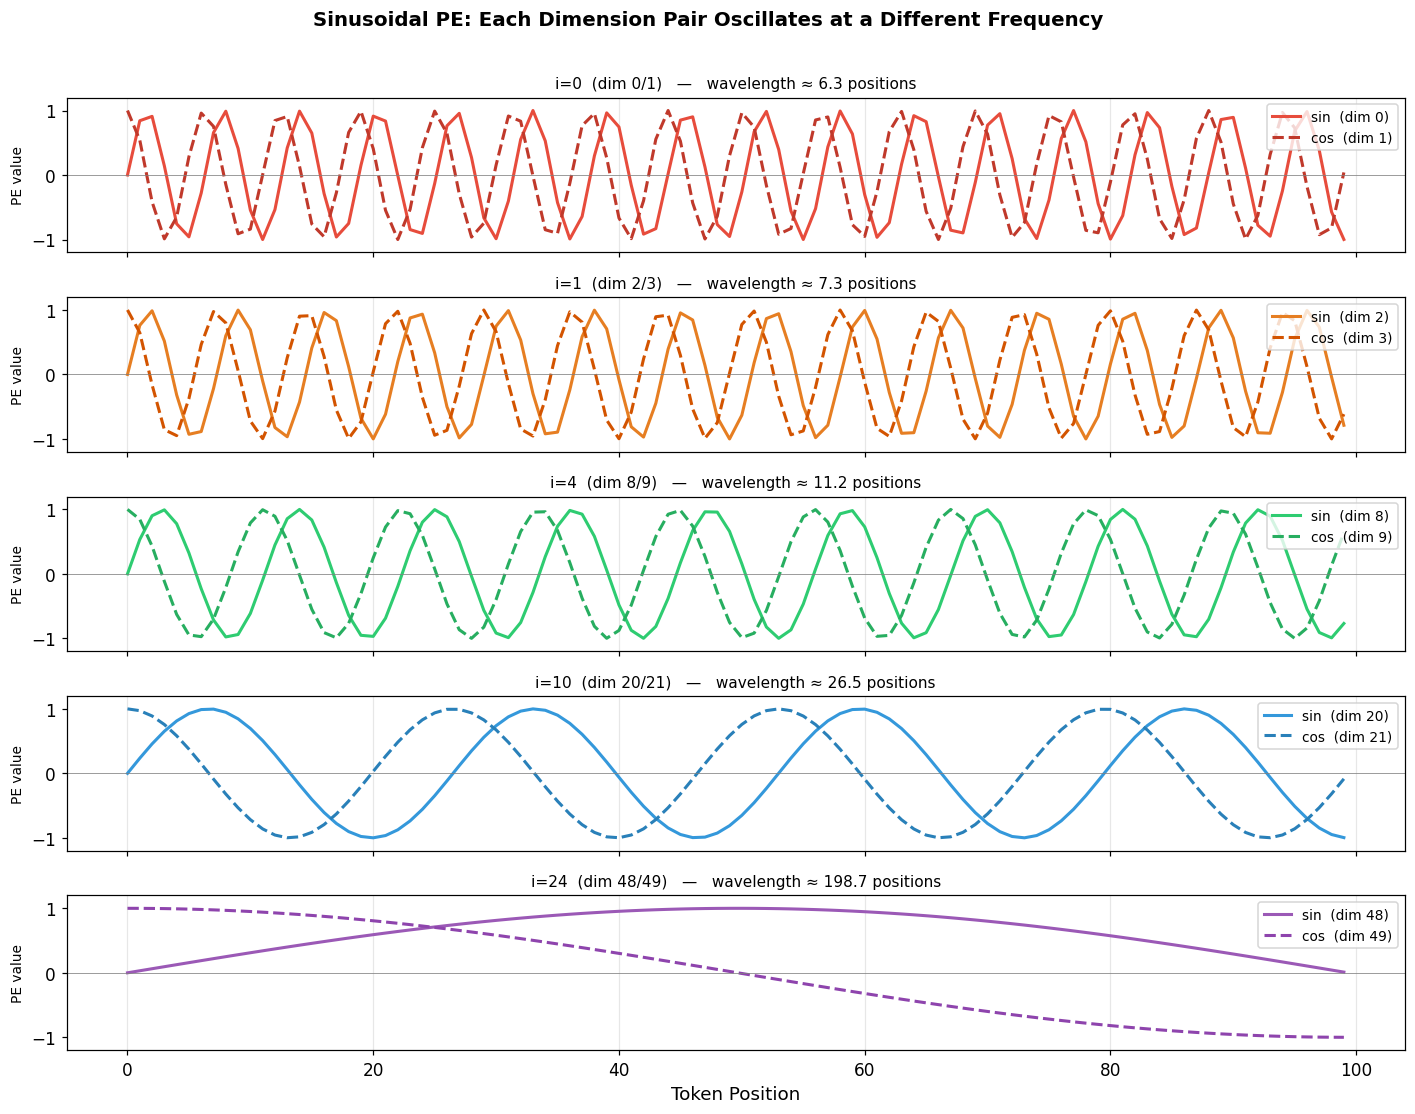

Low dimension pairs (top) = short wavelength = fine-grained position
High dimension pairs (bottom) = long wavelength = coarse position


In [5]:
# ── 4.2  Wave plots for selected dimension pairs ─────────────────────────────
PE_wave = sinusoidal_pe(max_len=100, d_model=128)
positions = np.arange(100)

dim_pairs = [0, 2, 8, 20, 48]    # dimension indices for sine  (even)
pair_labels = [f"i={p//2}  (dim {p}/{p+1})" for p in dim_pairs]

fig, axes = plt.subplots(len(dim_pairs), 1, figsize=(13, 10), sharex=True)
colors_sin = ['#e74c3c', '#e67e22', '#2ecc71', '#3498db', '#9b59b6']
colors_cos = ['#c0392b', '#d35400', '#27ae60', '#2980b9', '#8e44ad']

for ax, dim, label, cs, cc in zip(axes, dim_pairs, pair_labels, colors_sin, colors_cos):
    ax.plot(positions, PE_wave[:, dim],   color=cs, lw=2,   label=f'sin  (dim {dim})')
    ax.plot(positions, PE_wave[:, dim+1], color=cc, lw=2, ls='--', label=f'cos  (dim {dim+1})')
    ax.set_ylabel('PE value', fontsize=9)
    ax.set_ylim(-1.2, 1.2)
    ax.axhline(0, color='gray', lw=0.5)
    ax.legend(loc='upper right', fontsize=9)
    period = 2 * np.pi * (10000 ** (dim / 128))
    ax.set_title(f'{label}   —   wavelength ≈ {period:.1f} positions', fontsize=10)
    ax.grid(axis='x', alpha=0.3)

axes[-1].set_xlabel('Token Position', fontsize=12)
fig.suptitle('Sinusoidal PE: Each Dimension Pair Oscillates at a Different Frequency',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print("Low dimension pairs (top) = short wavelength = fine-grained position")
print("High dimension pairs (bottom) = long wavelength = coarse position")

### 4.3  PE + Token Embeddings: Adding Position to Meaning

The positional encoding is simply **added** to the token embedding:

$$\text{Input}_i = \text{TokenEmbedding}_i + \text{PE}_i$$

No concatenation — the model has the same dimensionality, but now every token's vector carries both **semantic** and **positional** information.

> **Why add instead of concatenate?**  
> Adding keeps the same `d_model` dimension.  
> Concatenating would double it, adding parameters and compute.  
> Adding works because the model's weight matrices can learn to separate the two signals if needed.

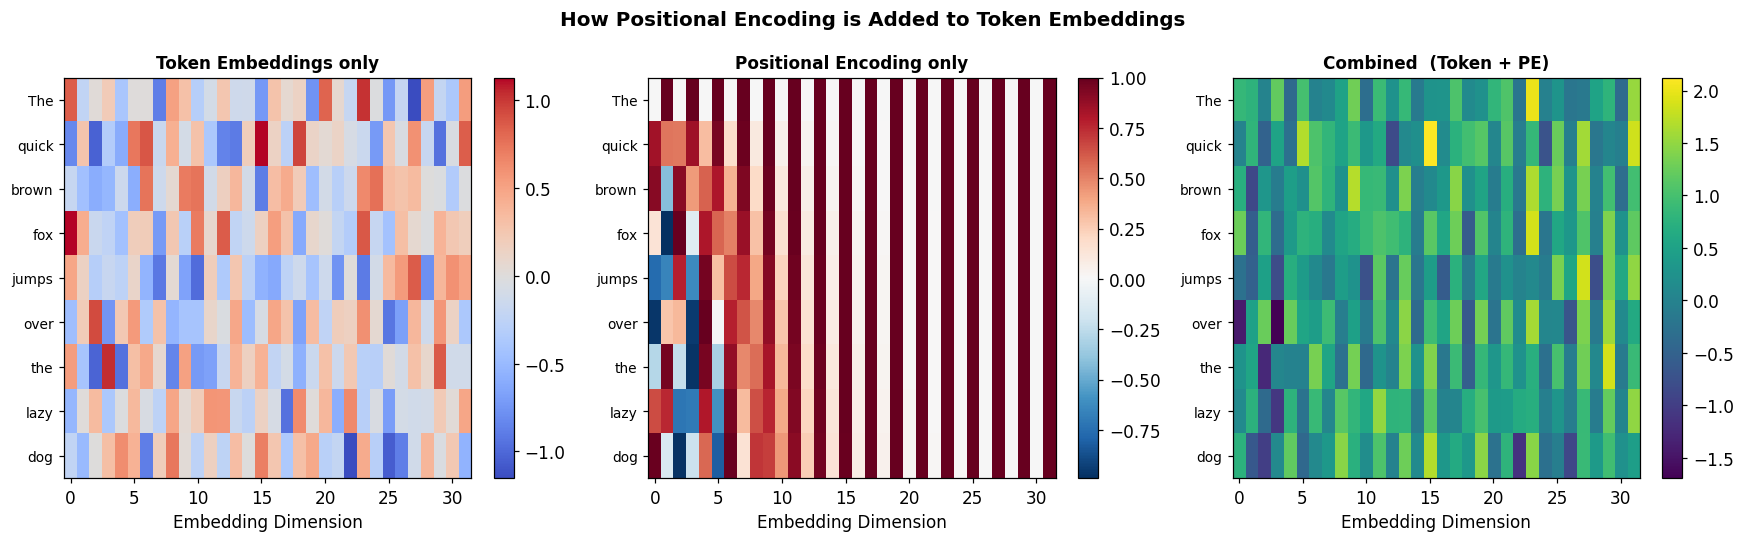

Each row in 'Combined' carries both the word's meaning AND its position in the sentence.


In [6]:
# ── 4.3  Visualise: token emb, PE, and combined ──────────────────────────────
sentence = "The quick brown fox jumps over the lazy dog".split()
n        = len(sentence)
d_model  = 32

np.random.seed(7)
token_emb = np.random.randn(n, d_model) * 0.5   # simulated token embeddings
PE_add    = sinusoidal_pe(max_len=n, d_model=d_model)
combined  = token_emb + PE_add

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
titles  = ['Token Embeddings only', 'Positional Encoding only', 'Combined  (Token + PE)']
arrays  = [token_emb, PE_add, combined]
cmaps   = ['coolwarm', 'RdBu_r', 'viridis']

for ax, arr, title, cmap in zip(axes, arrays, titles, cmaps):
    im = ax.imshow(arr, aspect='auto', cmap=cmap, interpolation='nearest')
    ax.set_yticks(range(n)); ax.set_yticklabels(sentence, fontsize=9)
    ax.set_xlabel('Embedding Dimension')
    ax.set_title(title, fontsize=11, fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.046)

fig.suptitle('How Positional Encoding is Added to Token Embeddings',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Each row in 'Combined' carries both the word's meaning AND its position in the sentence.")

---
## 5. Properties of Sinusoidal Encodings

### 5.1  Every Position is Unique
No two rows of the PE matrix are identical — any two positions can always be distinguished.

### 5.2  Relative Position via Linear Transformation

This is the key mathematical insight from the original paper.  
For any fixed offset $k$, there exists a **linear transformation matrix** $M_k$ (depending only on $k$, not on $pos$) such that:

$$PE_{pos+k} = M_k \cdot PE_{pos}$$

This uses the angle-addition identity:
$$\sin(a + b) = \sin(a)\cos(b) + \cos(a)\sin(b)$$
$$\cos(a + b) = \cos(a)\cos(b) - \sin(a)\sin(b)$$

**What this means for the model:** the Transformer can learn to identify relative distances simply by learning to apply certain linear transformations — it can generalise to gaps it has seen during training, and beyond.

### 5.3  Self-Attention Scores Encode Distance

Because PE vectors at nearby positions are more similar (high cosine similarity), the raw attention scores already carry implicit proximity information before training even begins.

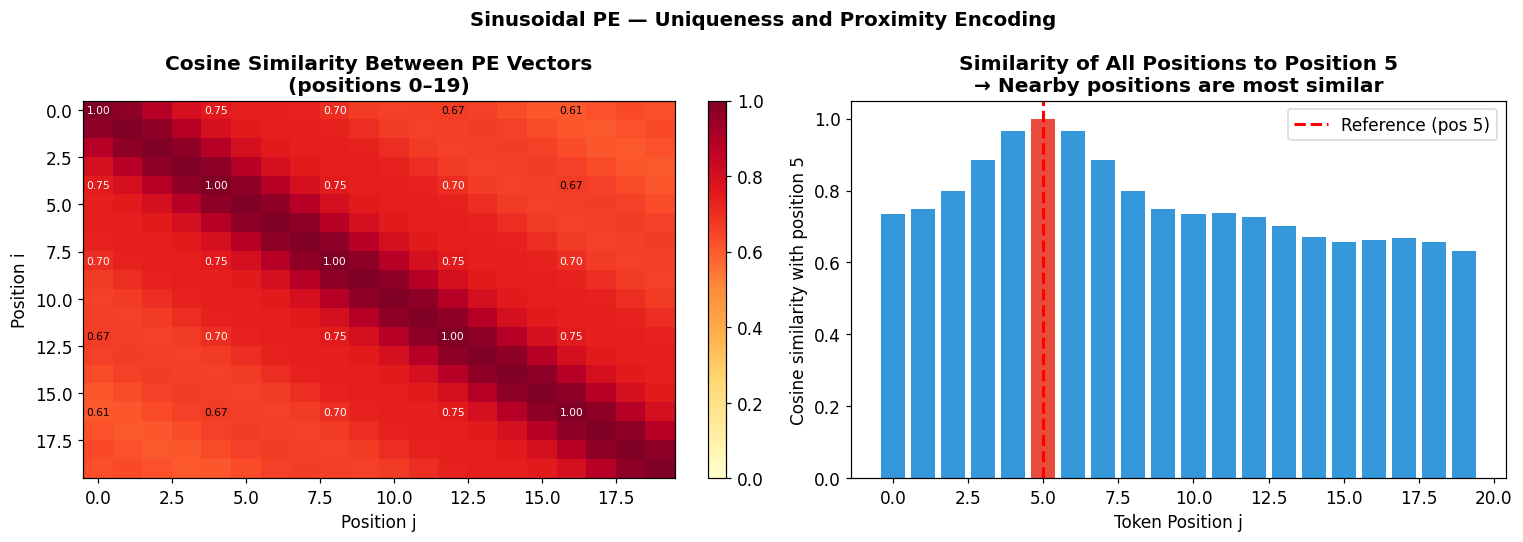

Diagonal = 1.0 (self-similarity). Off-diagonal < 1 → all positions unique.
Proximity: the closest positions have the highest similarity — distance is encoded!


In [7]:
# ── 5.1  Verify uniqueness: cosine similarity matrix of PE rows ──────────────
PE_prop = sinusoidal_pe(max_len=20, d_model=64)

# Cosine similarity between every pair of positions
norms = np.linalg.norm(PE_prop, axis=1, keepdims=True)
PE_norm = PE_prop / norms
cosine_sim = PE_norm @ PE_norm.T   # (20, 20)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
im = ax.imshow(cosine_sim, cmap='YlOrRd', vmin=0, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_title('Cosine Similarity Between PE Vectors\n(positions 0–19)',
             fontweight='bold')
ax.set_xlabel('Position j');  ax.set_ylabel('Position i')
for i in range(0, 20, 4):
    for j in range(0, 20, 4):
        ax.text(j, i, f'{cosine_sim[i,j]:.2f}', ha='center', va='center',
                fontsize=7, color='white' if cosine_sim[i,j] > 0.7 else 'black')

# 5.2  Demonstrate relative-position property: PE[pos+k] ≈ M_k · PE[pos]
ax = axes[1]
# Check: pairwise similarity should depend only on |i-j|
pos_ref = 5
similarities = [cosine_sim[pos_ref, j] for j in range(20)]
dists        = [abs(j - pos_ref) for j in range(20)]
ax.bar(range(20), similarities,
       color=['#e74c3c' if d == 0 else '#3498db' for d in dists])
ax.set_xlabel('Token Position j')
ax.set_ylabel('Cosine similarity with position 5')
ax.set_title('Similarity of All Positions to Position 5\n'
             '→ Nearby positions are most similar',
             fontweight='bold')
ax.axvline(pos_ref, color='red', lw=2, ls='--', label='Reference (pos 5)')
ax.legend()

plt.suptitle('Sinusoidal PE — Uniqueness and Proximity Encoding',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Diagonal = 1.0 (self-similarity). Off-diagonal < 1 → all positions unique.")
print("Proximity: the closest positions have the highest similarity — distance is encoded!")

In [8]:
# ── 5.3  Relative position: verify PE[pos+k] = M_k · PE[pos] ─────────────────
# For a single dimension pair (sin/cos), the rotation matrix M_k is exact.
# We demonstrate this numerically.

d_demo = 16
PE_rel = sinusoidal_pe(max_len=50, d_model=d_demo)   # verify the helper works

def sinusoidal_pe_single_pair(pos, i, d_model=128):
    """Return (sin, cos) for dimension pair i at position pos."""
    omega = 1.0 / (10000 ** (2*i / d_model))
    return np.sin(omega * pos), np.cos(omega * pos)

# For dim pair i=0, d_model=128:
pos, k, i_dim, d = 7, 3, 0, 128
sin_pos, cos_pos = sinusoidal_pe_single_pair(pos,   i_dim, d)
sin_pk,  cos_pk  = sinusoidal_pe_single_pair(pos+k, i_dim, d)
omega            = 1.0 / (10000 ** (2*i_dim / d))

# M_k rotation matrix for this frequency
M_k = np.array([
    [ np.cos(omega * k),  np.sin(omega * k)],
    [-np.sin(omega * k),  np.cos(omega * k)],
])
pe_pos  = np.array([sin_pos, cos_pos])
pe_pk_predicted = M_k @ pe_pos
pe_pk_actual    = np.array([sin_pk, cos_pk])

print("Relative Position Property: PE[pos+k] = M_k · PE[pos]")
print(f"  pos={pos}, k={k}, dim pair i={i_dim}")
print()
print(f"  PE[pos]          = {np.round(pe_pos, 6)}")
print(f"  PE[pos+k] actual = {np.round(pe_pk_actual, 6)}")
print(f"  M_k · PE[pos]    = {np.round(pe_pk_predicted, 6)}")
print()
print(f"  Match (within float precision): {np.allclose(pe_pk_actual, pe_pk_predicted)}")
print()
print("The rotation matrix M_k depends only on k (the offset),")
print("NOT on pos itself. This means relative distance is linearly representable.")

Relative Position Property: PE[pos+k] = M_k · PE[pos]
  pos=7, k=3, dim pair i=0

  PE[pos]          = [0.656987 0.753902]
  PE[pos+k] actual = [-0.544021 -0.839072]
  M_k · PE[pos]    = [-0.544021 -0.839072]

  Match (within float precision): True

The rotation matrix M_k depends only on k (the offset),
NOT on pos itself. This means relative distance is linearly representable.


---
## 6. Learned Positional Embeddings

Instead of computing positions from a formula, BERT and GPT simply **learn** a separate embedding matrix for positions:

```
PositionEmbeddingTable : shape (max_seq_len, d_model)   ← learned parameters
```

At training time, each position index $p \in \{0, 1, \ldots, L-1\}$ is used to look up the $p$-th row, just like a word embedding lookup.

### Comparison: Sinusoidal vs. Learned

| Property | Sinusoidal | Learned |
|----------|-----------|---------|
| Parameters | Zero (fixed formula) | `max_seq_len × d_model` extra params |
| Generalise beyond training length | Yes (formula works for any pos) | No (no embedding for unseen positions) |
| Optimised for the task | Fixed | Yes — adapts to the data |
| Encodes relative distance by design | Yes | Implicitly, if the task requires it |
| Used in | Original Transformer, T5 | BERT, GPT-2, GPT-3 |

> **Empirical finding:** BERT's authors tried both and reported "nearly identical results" — suggesting the structure of sinusoidal PE already happens to be close to what the model would learn anyway.

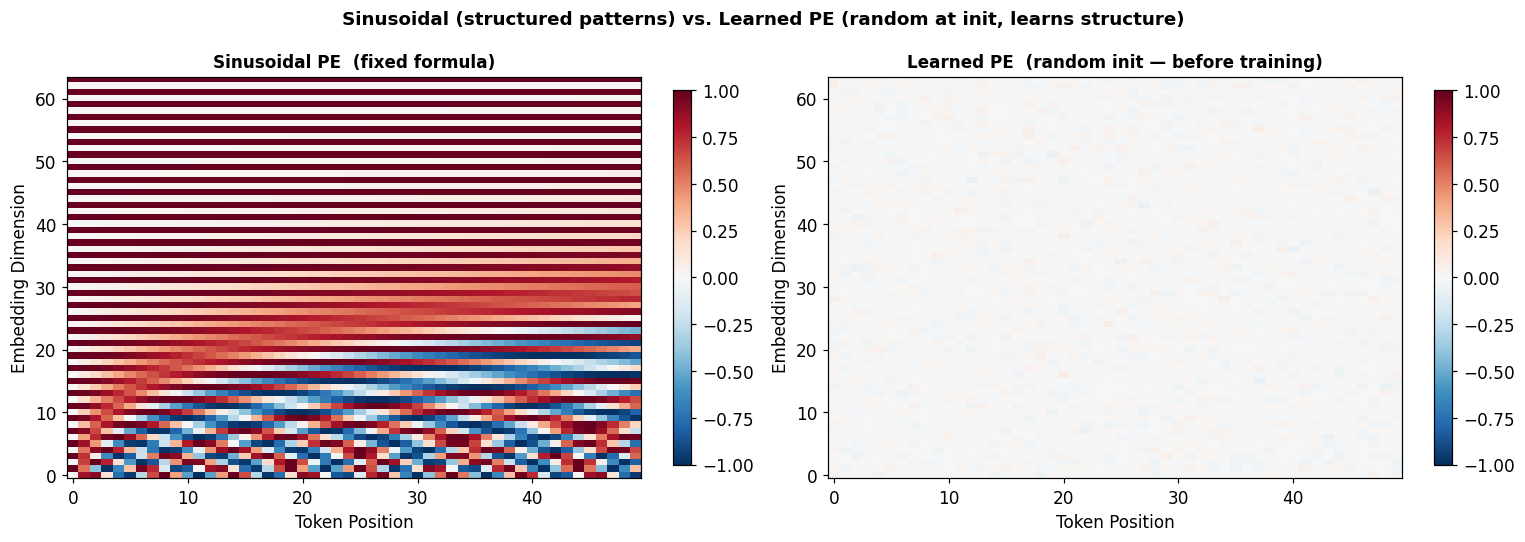

After training, the Learned PE matrix develops structure similar to
the sinusoidal pattern — suggesting sinusoidal is a principled choice.


In [9]:
class LearnedPositionalEmbedding:
    """
    Simplified BERT-style learned positional embedding.
    In real frameworks this is an nn.Embedding layer trained via backprop.
    Here we initialise it randomly to demonstrate the concept.
    """
    def __init__(self, max_len, d_model):
        # In practice these weights are updated by gradient descent
        self.embedding = np.random.randn(max_len, d_model) * 0.02
        self.max_len = max_len

    def __call__(self, seq_len):
        if seq_len > self.max_len:
            raise ValueError(f"seq_len {seq_len} exceeds max_len {self.max_len}")
        return self.embedding[:seq_len]   # (seq_len, d_model)


# ── Compare Sinusoidal vs. Learned (random init) visually ────────────────────
max_len = 50
d_model = 64

PE_sin    = sinusoidal_pe(max_len, d_model)
PE_learnt = LearnedPositionalEmbedding(max_len, d_model)(max_len)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, PE, title in zip(axes,
                          [PE_sin, PE_learnt],
                          ['Sinusoidal PE  (fixed formula)', 'Learned PE  (random init — before training)']):
    im = ax.imshow(PE.T, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1, origin='lower')
    ax.set_xlabel('Token Position');  ax.set_ylabel('Embedding Dimension')
    ax.set_title(title, fontsize=11, fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.03)

fig.suptitle('Sinusoidal (structured patterns) vs. Learned PE (random at init, learns structure)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("After training, the Learned PE matrix develops structure similar to")
print("the sinusoidal pattern — suggesting sinusoidal is a principled choice.")

---
## 7. Rotary Position Embeddings (RoPE)

RoPE is used in **LLaMA, Mistral, Gemma, Falcon, GPT-NeoX** and is becoming the de facto standard for modern LLMs.

### The Core Idea

Instead of adding a positional vector to the token embedding *before* computing Q and K, RoPE **rotates** the Query and Key vectors by an angle that depends on their position:

$$Q'_m = R_m \, Q_m \qquad K'_n = R_n \, K_n$$

where $R_p$ is a block-diagonal rotation matrix:

$$R_p = \begin{bmatrix} \cos(p\omega_0) & -\sin(p\omega_0) & & \\ \sin(p\omega_0) & \cos(p\omega_0) & & \\ & & \ddots & \\ & & & \cos(p\omega_{d/2-1}) & -\sin(p\omega_{d/2-1}) \\ & & & \sin(p\omega_{d/2-1}) & \cos(p\omega_{d/2-1}) \end{bmatrix}$$

### Why this is elegant

The attention score between query at position $m$ and key at position $n$ is:

$$Q'_m \cdot K'_n = (R_m Q_m)^T (R_n K_n) = Q_m^T \underbrace{R_m^T R_n}_{= R_{n-m}} K_n$$

The result depends only on **the relative offset** $n - m$, not on the absolute positions.  
Relative position is **baked in** to the attention score automatically.

### Advantages over Sinusoidal

| | Sinusoidal / Learned | RoPE |
|-|---------------------|------|
| Absolute position | Yes | Yes |
| Relative position encoded directly | Indirectly | Exactly |
| Works at inference for longer sequences | Sinusoidal: yes; Learned: no | With scaling tricks |
| Extra parameters | Learned only | None |

RoPE: attention scores depend only on RELATIVE position (pos_q - pos_k)
────────────────────────────────────────────────────────────
  Base pos =  0  | scores by offset [-3, -2, -1, 0, 1, 2, 3]: ['N/A', 'N/A', 'N/A', np.float64(-1.7852), np.float64(0.3606), np.float64(1.5394), np.float64(0.7846)]
  Base pos = 10  | scores by offset [-3, -2, -1, 0, 1, 2, 3]: [np.float64(-0.3239), np.float64(-2.3231), np.float64(-3.0368), np.float64(-1.7852), np.float64(0.3606), np.float64(1.5394), np.float64(0.7846)]
  Base pos = 50  | scores by offset [-3, -2, -1, 0, 1, 2, 3]: [np.float64(-0.3239), np.float64(-2.3231), np.float64(-3.0368), np.float64(-1.7852), np.float64(0.3606), np.float64(1.5394), np.float64(0.7846)]

Scores depend ONLY on the offset, not the absolute position.
→ The model generalises naturally to long sequences it has never seen.


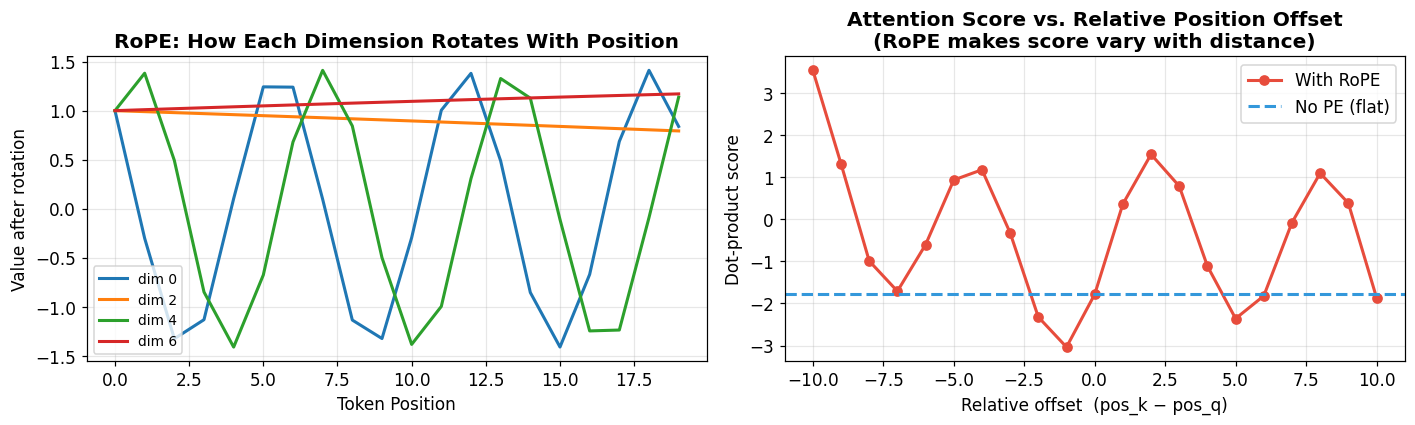

In [10]:
def rope_rotate(x, pos, base=10000):
    """
    Apply Rotary Position Embedding to a single vector x at position pos.

    x   : (d,)  where d must be even
    pos : int
    Returns x_rotated : (d,)
    """
    d = len(x)
    assert d % 2 == 0, "d must be even for RoPE"

    half = d // 2
    i_idx = np.arange(half)
    omega = 1.0 / (base ** (2 * i_idx / d))    # (half,)
    theta = pos * omega                          # (half,)

    x1 = x[:half]   # first half of dims
    x2 = x[half:]   # second half of dims

    # Apply 2D rotation to each (x1_i, x2_i) pair
    x1_rot = x1 * np.cos(theta) - x2 * np.sin(theta)
    x2_rot = x1 * np.sin(theta) + x2 * np.cos(theta)

    return np.concatenate([x1_rot, x2_rot])


def rope_attention_score(q, k, pos_q, pos_k):
    """Compute the attention score with RoPE applied to q and k."""
    q_rot = rope_rotate(q, pos_q)
    k_rot = rope_rotate(k, pos_k)
    return np.dot(q_rot, k_rot)


# ── Demonstrate relative-position property ───────────────────────────────────
d = 16
np.random.seed(3)
q = np.random.randn(d)
k = np.random.randn(d)

print("RoPE: attention scores depend only on RELATIVE position (pos_q - pos_k)")
print("─" * 60)
offsets = [-3, -2, -1, 0, 1, 2, 3]
for base_pos in [0, 10, 50]:
    scores = []
    for offset in offsets:
        pos_q = base_pos
        pos_k = base_pos + offset
        if pos_k < 0:
            scores.append(None)
            continue
        scores.append(rope_attention_score(q, k, pos_q, pos_k))

    valid_scores = [s for s in scores if s is not None]
    print(f"  Base pos = {base_pos:2d}  | scores by offset {offsets}: "
          f"{[round(s, 4) if s is not None else 'N/A' for s in scores]}")

print()
print("Scores depend ONLY on the offset, not the absolute position.")
print("→ The model generalises naturally to long sequences it has never seen.")

# ── Visualise RoPE rotation ───────────────────────────────────────────────────
positions = np.arange(20)
x_demo    = np.ones(8)     # unit vector for clarity
rotated   = np.array([rope_rotate(x_demo, p) for p in positions])  # (20, 8)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
for dim in range(0, 8, 2):
    ax.plot(positions, rotated[:, dim], label=f'dim {dim}', lw=2)
ax.set_title('RoPE: How Each Dimension Rotates With Position', fontweight='bold')
ax.set_xlabel('Token Position');  ax.set_ylabel('Value after rotation')
ax.legend(fontsize=9);  ax.grid(alpha=0.3)

ax = axes[1]
rel_deltas = range(-10, 11)
ref_pos    = 10
scores_rope  = [rope_attention_score(q, k, ref_pos, ref_pos + d) for d in rel_deltas]
scores_nopos = [np.dot(q, k)] * len(rel_deltas)

ax.plot(rel_deltas, scores_rope, 'o-', color='#e74c3c', label='With RoPE', lw=2)
ax.axhline(np.dot(q, k), color='#3498db', ls='--', label='No PE (flat)', lw=2)
ax.set_title('Attention Score vs. Relative Position Offset\n(RoPE makes score vary with distance)',
             fontweight='bold')
ax.set_xlabel('Relative offset  (pos_k − pos_q)');  ax.set_ylabel('Dot-product score')
ax.legend();  ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
## 8. Attention with Linear Biases (ALiBi)

**ALiBi** (Press et al., 2022; used in **MPT-7B, BLOOM**) takes a radical approach: **no positional embeddings at all** in the embedding layer or Q/K vectors.

Instead, it adds a static, non-learned linear bias directly to the pre-softmax attention score based on the distance between key and query tokens:

30643\text{Attention Scores} = \text{Softmax}\left( \frac{Q K^T}{\sqrt{d_k}} - m \cdot |i - j| \right)30643

Where $ is a fixed geometric slope specific to each attention head ( = 2^{-8/H}, 2^{-16/H}, \dots$).

### Why ALiBi Works So Well for Context Extrapolation:
- **Zero Positional Parameters**: No embedding table to learn or store.
- **Infinite Length Extrapolation**: A model trained on 2,048 tokens can extrapolate directly to 8,000+ tokens at inference time with zero performance degradation.

In [ ]:
def get_alibi_slopes(n_heads):
    """Compute geometric head slopes for ALiBi (Press et al., 2022)"""
    def get_slopes_power_of_2(n):
        start = (2 ** (-2 ** -(math.log2(n) - 3)))
        ratio = start
        return [start * (ratio ** i) for i in range(n)]
    import math
    return get_slopes_power_of_2(n_heads)

def alibi_attention_bias(seq_len, n_heads=8):
    """Generates [n_heads, seq_len, seq_len] bias matrix"""
    slopes = get_alibi_slopes(n_heads)
    # Relative distance matrix |i - j|
    positions = np.arange(seq_len)
    distance_matrix = np.abs(positions[:, None] - positions[None, :])
    
    # Multiply each head by its specific slope
    biases = np.array([-slope * distance_matrix for slope in slopes])
    return biases, slopes

biases, slopes = alibi_attention_bias(seq_len=16, n_heads=4)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for h in range(4):
    im = axes[h].imshow(biases[h], cmap="magma", vmin=-1.5, vmax=0)
    axes[h].set_title(f"Head {h+1} (Slope m={slopes[h]:.3f})", fontsize=10, fontweight="bold")
    axes[h].set_xlabel("Key Position")
    axes[h].set_ylabel("Query Position")

plt.suptitle("ALiBi: Head-Specific Linear Distance Penalties on Attention", y=1.05, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 9. End-to-End Transformer Encoder

Now that we understand both **Multi-Head Self-Attention** and **Positional Encodings**, we assemble them into a complete **Transformer Encoder** block in PyTorch using `nn.TransformerEncoderLayer` and `nn.TransformerEncoder`.

### Architecture:
```
           Input Tokens (Indices)
                     │
         [Token Embedding Layer]
                     │
           + [Positional Encoding]
                     │
       ┌─────────────▼─────────────┐
       │   LayerNorm & Residual    │
       │  Multi-Head Self-Attention│
       │   LayerNorm & Residual    │
       │    Feed-Forward Network   │
       └─────────────┬─────────────┘  x N Layers
                     ▼
           [Linear Output Head]
                     │
           Classification Logits
```

In [ ]:
import torch
import torch.nn as nn
import math

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, nhead, num_encoder_layers, num_classes, max_len=100):
        super(TransformerClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = PositionalEncoding(d_model, max_len)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=d_model*4, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_encoder_layers)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, src):
        # src: [batch_size, seq_len]
        emb = self.embedding(src)
        emb = self.pos_encoder(emb)
        encoded = self.transformer_encoder(emb)  # [batch_size, seq_len, d_model]
        # Pool across sequence (mean pooling)
        pooled = encoded.mean(dim=1)
        out = self.fc(pooled)
        return out

print("TransformerClassifier compiled successfully!")

In [ ]:
# Instantiate and train on synthetic sequence classification
input_vocab_size = 500
d_model = 64
nhead = 4
num_encoder_layers = 2
num_classes = 2
batch_size = 16
seq_len = 20

model = TransformerClassifier(input_vocab_size, d_model, nhead, num_encoder_layers, num_classes, max_len=seq_len)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Synthetic data
X_sample = torch.randint(0, input_vocab_size, (batch_size, seq_len))
y_sample = torch.randint(0, num_classes, (batch_size,))

# 5 Epochs of training demonstration
model.train()
print("Training Transformer Encoder on synthetic batch...")
for epoch in range(1, 6):
    optimizer.zero_grad()
    logits = model(X_sample)
    loss = criterion(logits, y_sample)
    loss.backward()
    optimizer.step()
    preds = logits.argmax(dim=-1)
    acc = (preds == y_sample).float().mean()
    print(f"Epoch {epoch}: Loss = {loss.item():.4f} | Accuracy = {acc.item()*100:.1f}%")

## 10. Summary & Key Takeaways

1. **Permutation Invariance**: Standard Self-Attention computes dot-product similarities without knowing sequence order ($QK^T$). Positional Encodings inject token order without breaking parallelization.
2. **Sinusoidal Positional Encoding**: Uses interleaved sine and cosine waves of different frequencies, allowing the model to attend to relative positions via linear transformations ($PE_{pos+k} = M_k PE_{pos}$).
3. **Modern Advances**:
   - **RoPE (Rotary Position Embedding)**: Rotates query and key vectors in complex 2D subspaces; standard in LLaMA, Mistral, and modern open-weights LLMs.
   - **ALiBi (Attention with Linear Biases)**: Applies a static distance penalty directly to the attention matrix, enabling length extrapolation to sequences longer than training context.
4. **The Complete Transformer**: Combining Multi-Head Attention, Positional Encoding, Residual Connections, and LayerNorm forms the universal backbone for modern generative and representation models.